# Đánh giá mô hình Random Forest phát hiện URL phishing — Hybrid-Guard

Báo cáo nghiên cứu theo đúng cấu trúc 16 mục của notebook LightGBM. Sử dụng artifact Random Forest đã huấn luyện và phân hoạch `partition` dành riêng cho kiểm tra. Nội dung gồm khoảng tin cậy bootstrap, ROC/PR, hiệu chuẩn, KS, SHAP tuỳ chọn, kiểm định chéo, learning curve, so sánh Decision Tree, phân tích lỗi và xuất kết quả.

Biểu đồ PNG 300 dpi/PDF và bảng CSV được lưu tại `artifacts/report/rf_research/`. Cross-validation, learning curve và SHAP tắt mặc định để lần chạy đầu không quá lâu; có thể bật trong mục 1.


## 1. Thiết lập và cấu hình

Ô này tự tìm thư mục dự án, dataset và mô hình đã huấn luyện. Giữ `THRESHOLD = 0.5` để kết quả khớp với lúc train. `N_BOOTSTRAP` điều khiển số lần lấy mẫu để tính khoảng tin cậy; tăng số này sẽ lâu hơn. Bật `RUN_CV`, `RUN_LEARNING_CURVE` hoặc `RUN_SHAP` nếu cần các phân tích mở rộng; các tuỳ chọn này mặc định tắt để lần chạy đầu nhanh hơn.

In [2]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    log_loss, matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

def find_project_root():
    starts = [Path.cwd().resolve(), Path.home() / 'Documents' / 'GitHub' / 'Hybrid-Guard']
    for start in starts:
        for candidate in (start, *start.parents):
            if (candidate / 'url_ml').is_dir() and (candidate / 'artifacts').is_dir():
                return candidate
    raise FileNotFoundError(
        'Không tìm thấy thư mục Hybrid-Guard. Hãy mở notebook từ workspace dự án '
        'hoặc kiểm tra đường dẫn Documents\\GitHub\\Hybrid-Guard.'
    )

PROJECT_ROOT = find_project_root()

DATA_PATH = PROJECT_ROOT.parent / 'Dataset.csv'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts' / 'rf_dataset'
MODEL_PATH = ARTIFACT_DIR / 'rf_dataset_model.joblib'
METRICS_PATH = ARTIFACT_DIR / 'training_metrics.json'
REPORT_DIR = PROJECT_ROOT / 'artifacts' / 'report' / 'rf_research'
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Không tìm thấy Dataset.csv tại: {DATA_PATH}')
if not MODEL_PATH.is_file() or not METRICS_PATH.is_file():
    raise FileNotFoundError(f'Thiếu mô hình hoặc metrics trong: {ARTIFACT_DIR}. Hãy train Random Forest trước.')
REPORT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOTSTRAP = 500
THRESHOLD = 0.5
CLASS_NAMES = ['Benign', 'Malicious']
COLORS = {'Random Forest': '#2ca02c', 'Benign': '#4c72b0', 'Malicious': '#dd8452'}

sns.set_theme(style='whitegrid', context='paper')
plt.rcParams.update({'font.family': 'serif', 'font.size': 10, 'figure.dpi': 110,
                     'savefig.dpi': 300, 'savefig.bbox': 'tight', 'grid.alpha': 0.35})

def save_fig(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(REPORT_DIR / f'{name}.{ext}')

print(f'Dataset: {DATA_PATH}')
print(f'Model:   {MODEL_PATH}')
print(f'Report:  {REPORT_DIR}')

# Các bước huấn luyện mở rộng có thể mất nhiều thời gian trên dataset lớn.
RUN_CV = False
CV_FOLDS = 5
RUN_LEARNING_CURVE = False
RUN_SHAP = False
SHAP_SAMPLE_SIZE = 500

Dataset: C:\Users\khanhtran\Documents\GitHub\Dataset.csv
Model:   C:\Users\khanhtran\Documents\GitHub\Hybrid-Guard\artifacts\rf_dataset\rf_dataset_model.joblib
Report:  C:\Users\khanhtran\Documents\GitHub\Hybrid-Guard\artifacts\report\rf_research


## 2. Mô hình và siêu tham số

In [22]:
if not MODEL_PATH.is_file() or not DATA_PATH.is_file():
    raise FileNotFoundError('Thiếu artifact mô hình hoặc Dataset.csv. Hãy chạy train_rf_dataset.py trước.')
artifact = joblib.load(MODEL_PATH)
model = artifact['model']
feature_names = list(artifact['feature_names'])
training = artifact.get('training', {})
stored_metrics = json.loads(METRICS_PATH.read_text(encoding='utf-8'))
params = model.get_params()

hyperparams = pd.DataFrame([
    ('Thuật toán', 'Random Forest Classifier'),
    ('Số cây', params['n_estimators']),
    ('Độ sâu tối đa', params['max_depth']),
    ('Class weight', params['class_weight']),
    ('Random state', params['random_state']),
    ('Số đặc trưng', len(feature_names)),
    ('Số dòng train', f"{training.get('train_rows', 0):,}"),
    ('Số dòng test', f"{training.get('test_rows', 0):,}"),
    ('Accuracy đã lưu', f"{stored_metrics['accuracy']:.4%}"),
], columns=['Tham số', 'Giá trị'])
display(hyperparams)

,Tham số,Giá trị
0,Thuật toán,Random Forest Classifier
1,Số cây,100
2,Độ sâu tối đa,25
3,Class weight,balanced
4,Random state,42
5,Số đặc trưng,25
6,Số dòng train,"520,616"
7,Số dòng test,"130,154"
8,Accuracy đã lưu,92.5027%


## 3. Mô tả dữ liệu

In [8]:
required = feature_names + ['Label', 'partition']
t0 = time.perf_counter()
df = pd.read_csv(DATA_PATH, usecols=required, low_memory=False)
df.columns = [str(c).strip().lstrip('\ufeff') for c in df.columns]
if df[required].isna().any().any():
    raise ValueError('Dataset có giá trị thiếu trong các cột cần đánh giá.')
partition = df['partition'].astype(str).str.strip().str.casefold()
if set(partition.unique()) != {'train', 'test'}:
    raise ValueError(f'partition phải gồm train/test, nhận được: {sorted(partition.unique())}')
X = df[feature_names].apply(pd.to_numeric, errors='raise').astype(float)
y = pd.to_numeric(df['Label'], errors='raise').astype(int).to_numpy()
test_mask = partition.eq('test').to_numpy()
X_test, y_test = X.loc[test_mask], y[test_mask]
if set(np.unique(y_test)) != {0, 1}:
    raise ValueError('Tập test phải có cả hai lớp 0 và 1.')

dataset_summary = pd.DataFrame([
    ('Tổng số URL', f'{len(df):,}'),
    ('Train', f'{int((partition == "train").sum()):,}'),
    ('Test', f'{len(y_test):,}'),
    ('Benign (0), test', f'{int((y_test == 0).sum()):,} ({(y_test == 0).mean():.2%})'),
    ('Malicious (1), test', f'{int((y_test == 1).sum()):,} ({(y_test == 1).mean():.2%})'),
    ('Số đặc trưng', len(feature_names)),
], columns=['Thuộc tính', 'Giá trị'])
display(Markdown('**Bảng 1.** Thống kê dữ liệu và tập đánh giá'))
display(dataset_summary)
print(f'Đọc và chuẩn bị dữ liệu trong {time.perf_counter() - t0:.1f}s')


**Bảng 1.** Thống kê dữ liệu và tập đánh giá

,Thuộc tính,Giá trị
0,Tổng số URL,"650,770"
1,Train,"520,616"
2,Test,"130,154"
3,"Benign (0), test","78,092 (60.00%)"
4,"Malicious (1), test","52,062 (40.00%)"
5,Số đặc trưng,25


Đọc và chuẩn bị dữ liệu trong 0.8s


## 4. Tái lập tập kiểm tra (hold-out)

Sử dụng phân hoạch train/test có sẵn trong dataset và đối chiếu ma trận nhầm lẫn với artifact để xác nhận kết quả tái lập.

In [9]:
t0 = time.perf_counter()
y_score = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test).astype(int)
latency_us = (time.perf_counter() - t0) / len(y_test) * 1e6
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(f'Confusion matrix tái lập: {cm.tolist()}')
print(f"Confusion matrix lúc train: {stored_metrics['confusion_matrix']}")
if not np.array_equal(cm, np.asarray(stored_metrics['confusion_matrix'])):
    raise AssertionError('Kết quả không khớp artifact; kiểm tra dataset/model có đồng bộ không.')
print(f'Thời gian dự đoán batch: {latency_us:.2f} µs/URL')

Confusion matrix tái lập: [[72990, 5102], [4656, 47406]]
Confusion matrix lúc train: [[72990, 5102], [4656, 47406]]
Thời gian dự đoán batch: 3.65 µs/URL


## 5. Chỉ số tổng hợp + khoảng tin cậy 95%

In [10]:
metric_functions = {
    'Accuracy': lambda a, p, s: accuracy_score(a, p),
    'Balanced accuracy': lambda a, p, s: balanced_accuracy_score(a, p),
    'Precision': lambda a, p, s: precision_score(a, p, zero_division=0),
    'Recall (TPR)': lambda a, p, s: recall_score(a, p, zero_division=0),
    'F1-score': lambda a, p, s: f1_score(a, p, zero_division=0),
    'ROC-AUC': lambda a, p, s: roc_auc_score(a, s),
    'PR-AUC (AP)': lambda a, p, s: average_precision_score(a, s),
    'MCC': lambda a, p, s: matthews_corrcoef(a, p),
    'Log loss': lambda a, p, s: log_loss(a, s),
    'Brier score': lambda a, p, s: brier_score_loss(a, s),
}
point = {name: float(fn(y_test, y_pred, y_score)) for name, fn in metric_functions.items()}
rng = np.random.default_rng(int(training.get('random_state', 42)))
bootstrap = {name: [] for name in point}
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_test), len(y_test))
    if np.unique(y_test[idx]).size < 2:
        continue
    for name, fn in metric_functions.items():
        bootstrap[name].append(float(fn(y_test[idx], y_pred[idx], y_score[idx])))
metrics_table = pd.DataFrame([
    {'Chỉ số': name, 'Giá trị': value,
     'CI 95% dưới': np.quantile(bootstrap[name], 0.025),
     'CI 95% trên': np.quantile(bootstrap[name], 0.975)}
    for name, value in point.items()
])
display(Markdown(f'**Bảng 2.** Hiệu năng trên tập test (n = {len(y_test):,}; bootstrap = {N_BOOTSTRAP})'))
display(metrics_table.round(4))
report = pd.DataFrame(classification_report(
    y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0
)).T
display(Markdown('**Bảng 3.** Classification report'))
display(report.round(4))
metrics_table.to_csv(REPORT_DIR / 'metrics_with_ci.csv', index=False)
report.to_csv(REPORT_DIR / 'classification_report.csv')

**Bảng 2.** Hiệu năng trên tập test (n = 130,154; bootstrap = 500)

,Chỉ số,Giá trị,CI 95% dưới,CI 95% trên
0,Accuracy,0.9250,0.9237,0.9266
1,Balanced accuracy,0.9226,0.9212,0.9242
2,Precision,0.9028,0.9004,0.9052
3,Recall (TPR),0.9106,0.9083,0.9129
4,F1-score,0.9067,0.9049,0.9086
5,ROC-AUC,0.9737,0.9728,0.9745
6,PR-AUC (AP),0.9711,0.9702,0.9719
7,MCC,0.8441,0.8412,0.8471
8,Log loss,0.2043,0.2014,0.2073
9,Brier score,0.0584,0.0576,0.0592


**Bảng 3.** Classification report

,precision,recall,f1-score,support
Benign,0.9400,0.9347,0.9373,78092.000
Malicious,0.9028,0.9106,0.9067,52062.000
accuracy,0.9250,0.9250,0.9250,0.925
macro avg,0.9214,0.9226,0.9220,130154.000
weighted avg,0.9252,0.9250,0.9251,130154.000


## 6. Ma trận nhầm lẫn

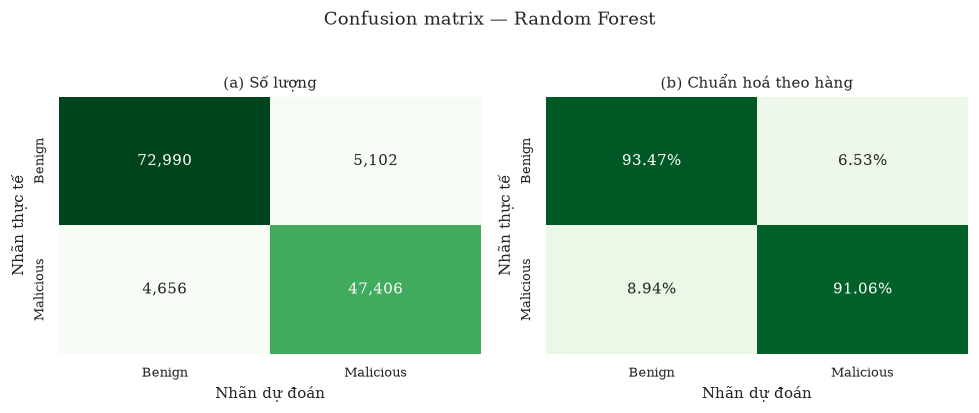

In [11]:
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Greens', cbar=False, ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title('(a) Số lượng')
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', cbar=False, ax=axes[1], vmin=0, vmax=1,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_title('(b) Chuẩn hoá theo hàng')
for ax in axes:
    ax.set_xlabel('Nhãn dự đoán')
    ax.set_ylabel('Nhãn thực tế')
fig.suptitle('Confusion matrix — Random Forest', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig1_confusion_matrix')
plt.show()

## 7. Đường cong ROC và Precision–Recall

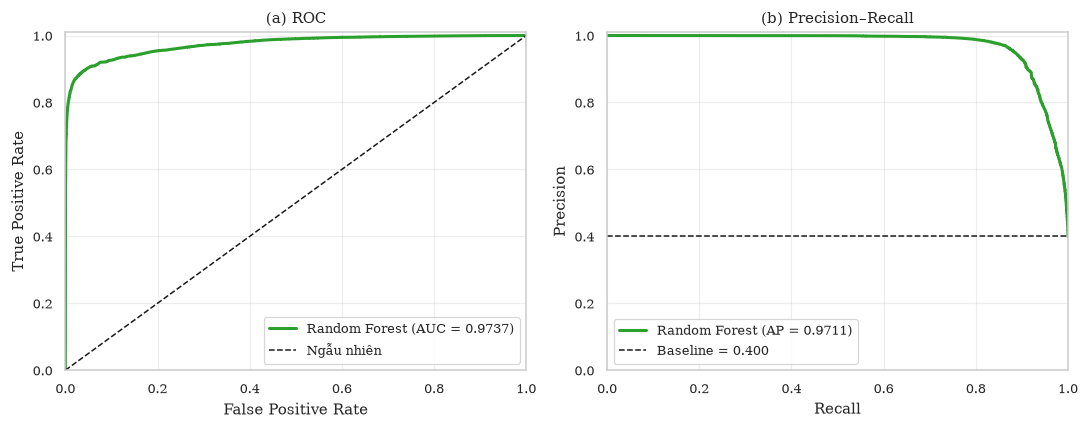

In [12]:
fpr, tpr, _ = roc_curve(y_test, y_score)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_score)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, color=COLORS['Random Forest'], lw=2,
             label=f"Random Forest (AUC = {point['ROC-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Ngẫu nhiên')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='(a) ROC', xlim=(0, 1), ylim=(0, 1.01))
axes[0].legend(loc='lower right')
axes[1].plot(recall_curve, precision_curve, color=COLORS['Random Forest'], lw=2,
             label=f"Random Forest (AP = {point['PR-AUC (AP)']:.4f})")
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Baseline = {y_test.mean():.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='(b) Precision–Recall', xlim=(0, 1), ylim=(0, 1.01))
axes[1].legend(loc='lower left')
fig.tight_layout()
save_fig(fig, 'fig2_roc_pr')
plt.show()

## 8. Phân tích ngưỡng quyết định

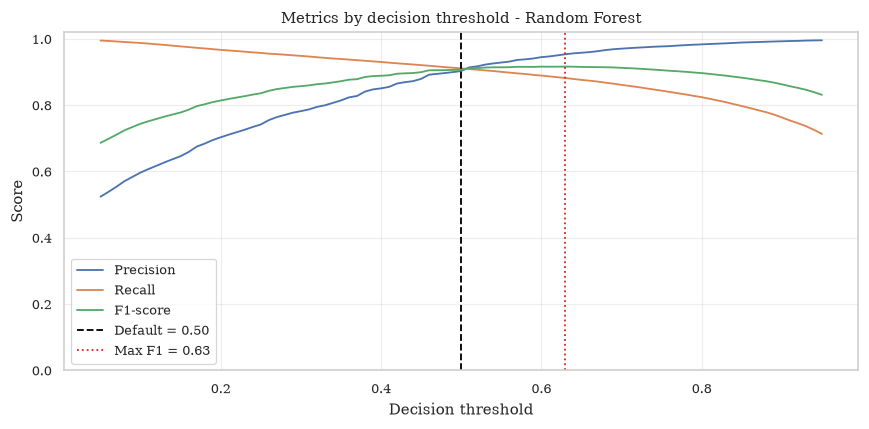

Ngưỡng tối đa F1 trong lưới: **0.63** (F1 = 0.9161). Chọn ngưỡng triển khai cần cân nhắc chi phí cảnh báo nhầm và bỏ sót.

In [13]:
thresholds = np.linspace(0.05, 0.95, 91)
threshold_rows = []
for threshold in thresholds:
    pred = (y_score >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
    })
threshold_table = pd.DataFrame(threshold_rows)
best_row = threshold_table.loc[threshold_table['F1-score'].idxmax()]
fig, ax = plt.subplots(figsize=(8, 4))
for column in ['Precision', 'Recall', 'F1-score']:
    ax.plot(threshold_table['Threshold'], threshold_table[column], label=column)
ax.axvline(THRESHOLD, color='black', ls='--', label=f'Default = {THRESHOLD:.2f}')
ax.axvline(best_row['Threshold'], color='tab:red', ls=':', label=f"Max F1 = {best_row['Threshold']:.2f}")
ax.set(xlabel='Decision threshold', ylabel='Score', title='Metrics by decision threshold - Random Forest', ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
save_fig(fig, 'fig3_threshold_analysis')
plt.show()
display(Markdown(f"Ngưỡng tối đa F1 trong lưới: **{best_row['Threshold']:.2f}** (F1 = {best_row['F1-score']:.4f}). Chọn ngưỡng triển khai cần cân nhắc chi phí cảnh báo nhầm và bỏ sót."))
threshold_table.to_csv(REPORT_DIR / 'threshold_analysis.csv', index=False)

## 9. Hiệu chuẩn xác suất (calibration)

Biểu đồ reliability so sánh xác suất dự đoán với tỷ lệ dương tính quan sát được trong từng khoảng xác suất.

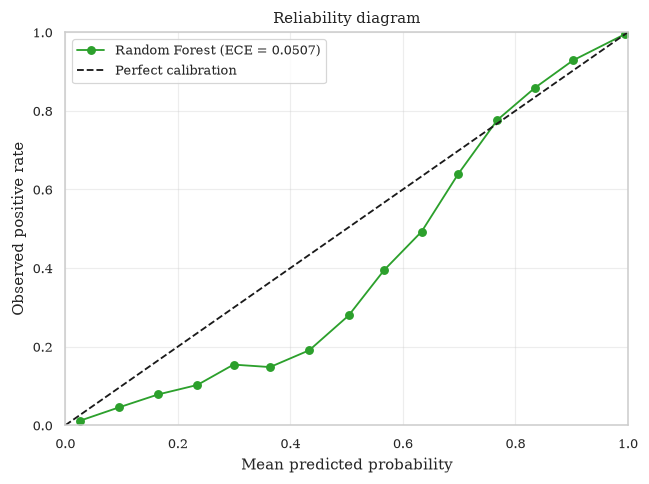

,Mean predicted probability,Observed positive rate
0,0.0253,0.0111
1,0.0955,0.0455
2,0.1651,0.0784
3,0.2347,0.1025
4,0.2989,0.1543
5,0.3638,0.1480
6,0.4336,0.1908
7,0.5036,0.2793
8,0.5669,0.3952
9,0.6333,0.4928


In [14]:
frac_pos, mean_pred = calibration_curve(y_test, y_score, n_bins=15, strategy='uniform')
calibration_table = pd.DataFrame({'Mean predicted probability': mean_pred, 'Observed positive rate': frac_pos})
bin_ids = np.minimum((y_score * 15).astype(int), 14)
bin_counts = np.bincount(bin_ids, minlength=15)
calibration_error = float(np.average(np.abs(frac_pos - mean_pred), weights=bin_counts[bin_counts > 0]))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(mean_pred, frac_pos, 'o-', color=COLORS['Random Forest'], label=f'Random Forest (ECE = {calibration_error:.4f})')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set(xlabel='Mean predicted probability', ylabel='Observed positive rate', title='Reliability diagram', xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
save_fig(fig, 'fig4_calibration')
plt.show()
display(calibration_table.round(4))
calibration_table.to_csv(REPORT_DIR / 'calibration.csv', index=False)


## 10. Phân phối điểm và thống kê KS

Thống kê Kolmogorov–Smirnov đo độ tách biệt giữa phân phối điểm dự đoán của URL benign và malicious.

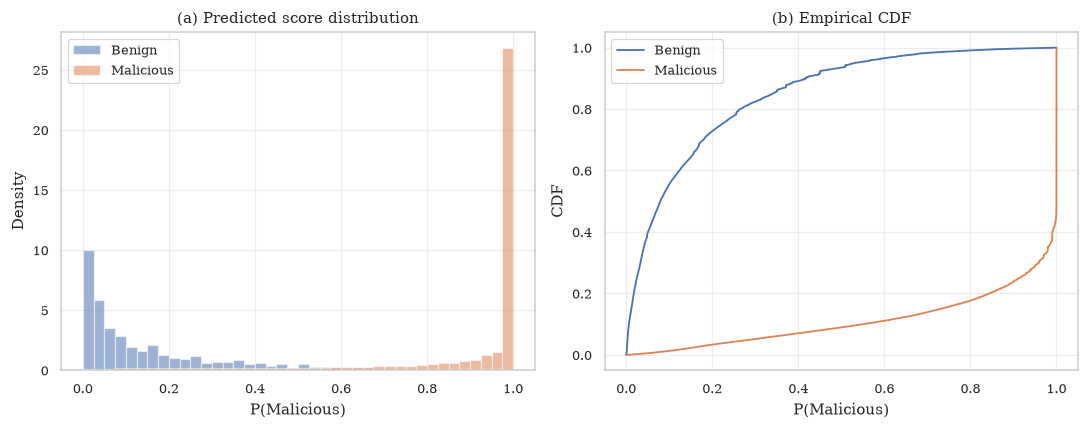

,KS statistic,p-value,Benign n,Malicious n
0,0.855051,0.0,78092,52062


In [15]:
from scipy.stats import ks_2samp

scores_benign = y_score[y_test == 0]
scores_malicious = y_score[y_test == 1]
ks_result = ks_2samp(scores_malicious, scores_benign)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(scores_benign, bins=40, density=True, alpha=0.55, label='Benign', color=COLORS['Benign'])
axes[0].hist(scores_malicious, bins=40, density=True, alpha=0.55, label='Malicious', color=COLORS['Malicious'])
axes[0].set(xlabel='P(Malicious)', ylabel='Density', title='(a) Predicted score distribution')
axes[0].legend()
for values, label, color in [(scores_benign, 'Benign', COLORS['Benign']), (scores_malicious, 'Malicious', COLORS['Malicious'])]:
    ordered = np.sort(values)
    axes[1].plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), label=label, color=color)
axes[1].set(xlabel='P(Malicious)', ylabel='CDF', title='(b) Empirical CDF')
axes[1].legend()
fig.tight_layout()
save_fig(fig, 'fig5_score_distribution_ks')
plt.show()
ks_table = pd.DataFrame([{'KS statistic': ks_result.statistic, 'p-value': ks_result.pvalue,
                          'Benign n': len(scores_benign), 'Malicious n': len(scores_malicious)}])
display(ks_table)
ks_table.to_csv(REPORT_DIR / 'ks_test.csv', index=False)


## 11. Độ quan trọng đặc trưng và SHAP

Báo cáo độ quan trọng Gini cho từng đặc trưng. SHAP là tuỳ chọn; cài `shap` và đặt `RUN_SHAP = True` trong mục 1 để chạy.

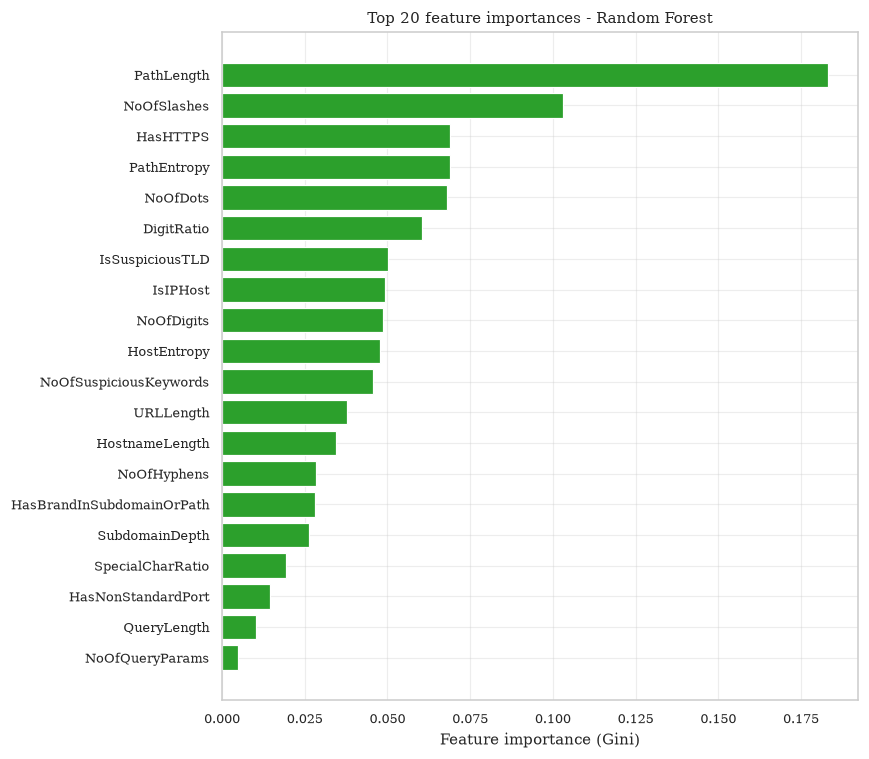

,Feature,Importance
0,PathLength,0.183063
1,NoOfSlashes,0.102927
2,HasHTTPS,0.069024
3,PathEntropy,0.068867
4,NoOfDots,0.068054
5,DigitRatio,0.060389
6,IsSuspiciousTLD,0.050269
7,IsIPHost,0.049338
8,NoOfDigits,0.048716
9,HostEntropy,0.047796


In [16]:
importance = pd.DataFrame({'Feature': feature_names, 'Importance': model.feature_importances_})
importance = importance.sort_values('Importance', ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
top_features = importance.head(20).sort_values('Importance')
ax.barh(top_features['Feature'], top_features['Importance'], color=COLORS['Random Forest'])
ax.set(xlabel='Feature importance (Gini)', title='Top 20 feature importances - Random Forest')
fig.tight_layout()
save_fig(fig, 'fig6_feature_importance')
plt.show()
display(importance.head(20).reset_index(drop=True))
importance.to_csv(REPORT_DIR / 'feature_importance.csv', index=False)
if RUN_SHAP:
    try:
        import shap
    except ImportError as exc:
        raise ImportError('SHAP is enabled but not installed. Run pip install shap or set RUN_SHAP = False.') from exc
    X_shap = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=42)
    shap_values = shap.TreeExplainer(model).shap_values(X_shap)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif getattr(shap_values, 'ndim', 0) == 3:
        shap_values = shap_values[:, :, 1]
    shap.summary_plot(shap_values, X_shap, feature_names=feature_names, show=False, max_display=20)
    fig = plt.gcf()
    fig.tight_layout()
    save_fig(fig, 'fig7_shap_summary')
    plt.show()


## 12. Kiểm định chéo phân tầng k-fold

In [17]:
if RUN_CV:
    from sklearn.base import clone
    from sklearn.model_selection import StratifiedKFold
    X_train = X.loc[partition.eq('train')]
    y_train = pd.to_numeric(df.loc[partition.eq('train'), 'Label'], errors='raise').astype(int).to_numpy()
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)
    rows = []
    for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
        fold_model = clone(model).fit(X_train.iloc[fit_idx], y_train[fit_idx])
        fold_score = fold_model.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_pred = (fold_score >= THRESHOLD).astype(int)
        rows.append({'Fold': fold, 'Accuracy': accuracy_score(y_train[val_idx], fold_pred),
                     'F1': f1_score(y_train[val_idx], fold_pred), 'ROC-AUC': roc_auc_score(y_train[val_idx], fold_score)})
    cv_table = pd.DataFrame(rows)
    display(cv_table.round(4))
    display(cv_table[['Accuracy', 'F1', 'ROC-AUC']].agg(['mean', 'std']).round(4))
    cv_table.to_csv(REPORT_DIR / 'cross_validation.csv', index=False)
else:
    print('Cross-validation is disabled to keep the first run shorter. Set RUN_CV = True in section 1 to run it.')


Cross-validation is disabled to keep the first run shorter. Set RUN_CV = True in section 1 to run it.


## 13. Learning curve

In [18]:
if RUN_LEARNING_CURVE:
    from sklearn.base import clone
    X_train = X.loc[partition.eq('train')]
    y_train = pd.to_numeric(df.loc[partition.eq('train'), 'Label'], errors='raise').astype(int).to_numpy()
    order = np.random.default_rng(42).permutation(len(X_train))
    rows = []
    for fraction in [0.05, 0.1, 0.25, 0.5, 1.0]:
        n = max(2, int(len(order) * fraction))
        lc_model = clone(model).fit(X_train.iloc[order[:n]], y_train[order[:n]])
        train_pred = lc_model.predict(X_train.iloc[order[:n]])
        test_pred = lc_model.predict(X_test)
        rows.append({'Train rows': n, 'Train F1': f1_score(y_train[order[:n]], train_pred),
                     'Test F1': f1_score(y_test, test_pred)})
    learning_table = pd.DataFrame(rows)
    display(learning_table.round(4))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(learning_table['Train rows'], learning_table['Train F1'], 'o-', label='Train F1')
    ax.plot(learning_table['Train rows'], learning_table['Test F1'], 'o-', label='Test F1')
    ax.set(xlabel='Number of training rows', ylabel='F1-score', title='Learning curve - Random Forest')
    ax.legend()
    fig.tight_layout()
    save_fig(fig, 'fig8_learning_curve')
    plt.show()
    learning_table.to_csv(REPORT_DIR / 'learning_curve.csv', index=False)
else:
    print('Learning curve is disabled because it retrains multiple forests. Set RUN_LEARNING_CURVE = True in section 1 to run.')


Learning curve is disabled because it retrains multiple forests. Set RUN_LEARNING_CURVE = True in section 1 to run.


## 14. So sánh với Decision Tree (McNemar + paired bootstrap)

Hai mô hình sử dụng cùng các đặc trưng và cùng phân hoạch train/test để so sánh công bằng.

In [19]:
from scipy.stats import binomtest
from sklearn.tree import DecisionTreeClassifier
X_train = X.loc[partition.eq('train')]
y_train = pd.to_numeric(df.loc[partition.eq('train'), 'Label'], errors='raise').astype(int).to_numpy()
dt_model = DecisionTreeClassifier(max_depth=25, random_state=42, class_weight='balanced').fit(X_train, y_train)
dt_score = dt_model.predict_proba(X_test)[:, 1]
dt_pred = (dt_score >= THRESHOLD).astype(int)
comparison_table = pd.DataFrame([
    {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'F1': f1_score(y_test, pred),
     'ROC-AUC': roc_auc_score(y_test, score), 'PR-AUC': average_precision_score(y_test, score)}
    for name, score, pred in [('Random Forest', y_score, y_pred), ('Decision Tree', dt_score, dt_pred)]
])
display(comparison_table.round(4))
rf_correct, dt_correct = y_pred == y_test, dt_pred == y_test
b = int(np.sum(rf_correct & ~dt_correct)); c = int(np.sum(~rf_correct & dt_correct))
mcnemar_p = float(binomtest(min(b, c), b + c, 0.5).pvalue) if b + c else 1.0
rng = np.random.default_rng(42); diff_f1 = []
for _ in range(300):
    idx = rng.integers(0, len(y_test), len(y_test))
    diff_f1.append(f1_score(y_test[idx], y_pred[idx], zero_division=0) - f1_score(y_test[idx], dt_pred[idx], zero_division=0))
comparison_tests = pd.DataFrame([{'RF correct / DT wrong': b, 'RF wrong / DT correct': c,
    'McNemar exact p-value': mcnemar_p,
    'Paired bootstrap F1 difference (RF-DT)': f1_score(y_test, y_pred) - f1_score(y_test, dt_pred),
    'F1 difference CI 2.5%': np.quantile(diff_f1, 0.025), 'F1 difference CI 97.5%': np.quantile(diff_f1, 0.975)}])
display(comparison_tests.round(5))
comparison_table.to_csv(REPORT_DIR / 'model_comparison.csv', index=False)
comparison_tests.to_csv(REPORT_DIR / 'model_comparison_tests.csv', index=False)


,Model,Accuracy,F1,ROC-AUC,PR-AUC
0,Random Forest,0.9250,0.9067,0.9737,0.9711
1,Decision Tree,0.9048,0.8825,0.9110,0.8656


,RF correct / DT wrong,RF wrong / DT correct,McNemar exact p-value,Paired bootstrap F1 difference (RF-DT),F1 difference CI 2.5%,F1 difference CI 97.5%
0,5404,2774,0.0,0.02421,0.02237,0.02579


## 15. Phân tích lỗi

In [20]:
tn, fp, fn, tp = cm.ravel()
error_positions = np.flatnonzero(y_pred != y_test)
confidence = np.where(y_pred == 1, y_score, 1 - y_score)
errors = pd.DataFrame({'Actual': np.where(y_test[error_positions] == 1, 'Malicious', 'Benign'),
    'Predicted': np.where(y_pred[error_positions] == 1, 'Malicious', 'Benign'),
    'Malicious probability': y_score[error_positions], 'Prediction confidence': confidence[error_positions]})
if len(error_positions):
    errors = pd.concat([errors.reset_index(drop=True), X_test.iloc[error_positions].reset_index(drop=True)], axis=1)
    errors = errors.sort_values('Prediction confidence', ascending=False)
error_summary = pd.DataFrame([('True negative', int(tn)), ('False positive', int(fp)),
    ('False negative', int(fn)), ('True positive', int(tp))], columns=['Outcome', 'Count'])
display(error_summary)
display(Markdown('**Top 20 highest-confidence errors**'))
display(errors.head(20))


,Outcome,Count
0,True negative,72990
1,False positive,5102
2,False negative,4656
3,True positive,47406


**Top 20 highest-confidence errors**

,Actual,Predicted,Malicious probability,Prediction confidence,URLLength,HostnameLength,PathLength,QueryLength,NoOfDots,NoOfHyphens,...,IsIPHost,SubdomainDepth,IsSuspiciousTLD,IsPunycode,HasHTTPS,HasNonStandardPort,NoOfSuspiciousKeywords,HasBrandInSubdomainOrPath,IsShortener,HasEmbeddedURL
4818,Benign,Malicious,1.000000,1.000000,18.0,9.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6228,Benign,Malicious,1.000000,1.000000,38.0,31.0,0.0,0.0,3.0,0.0,...,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4180,Benign,Malicious,1.000000,1.000000,47.0,38.0,1.0,0.0,2.0,2.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
757,Benign,Malicious,1.000000,1.000000,18.0,11.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1748,Benign,Malicious,1.000000,1.000000,22.0,14.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7411,Benign,Malicious,1.000000,1.000000,40.0,31.0,1.0,0.0,3.0,1.0,...,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1196,Malicious,Benign,0.000000,1.000000,15.0,7.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8794,Benign,Malicious,1.000000,1.000000,26.0,17.0,1.0,0.0,3.0,0.0,...,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6705,Benign,Malicious,1.000000,1.000000,41.0,32.0,1.0,0.0,3.0,1.0,...,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6718,Benign,Malicious,1.000000,1.000000,43.0,14.0,22.0,0.0,4.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 16. Xuất kết quả và tóm tắt

In [24]:
required_state = [
    'partition', 'importance', 'metrics_table', 'DATA_PATH', 'THRESHOLD',
    'point', 'ks_result', 'best_row', 'latency_us', 'RUN_CV',
    'RUN_LEARNING_CURVE', 'RUN_SHAP', 'df', 'y_test', 'y_pred',
    'feature_names', 'params', 'error_summary', 'REPORT_DIR',
]
missing_state = [name for name in required_state if name not in globals()]
if missing_state:
    raise RuntimeError(
        'Mục 16 cần kết quả từ các mục trước. Hãy chạy toàn bộ notebook từ đầu '
        f'trước khi chạy mục 16. Đang thiếu: {", ".join(missing_state)}'
    )

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
n_train = int((partition == 'train').sum())
n_test = int((partition == 'test').sum())
fpr_value = fp / (fp + tn) if fp + tn else 0.0
fnr_value = fn / (fn + tp) if fn + tp else 0.0
top_features = importance.head(5)
top_feature_text = ', '.join(f"{row.Feature} ({row.Importance:.1%})" for row in top_features.itertuples())

def confidence_interval(metric_name):
    row = metrics_table.loc[metrics_table['Chỉ số'] == metric_name]
    if row.empty:
        return 'N/A'
    return f"[{row.iloc[0]['CI 95% dưới']:.4f}, {row.iloc[0]['CI 95% trên']:.4f}]"

comparison_line = 'Chưa có kết quả so sánh Decision Tree.'
if 'comparison_table' in globals():
    rf_row = comparison_table.loc[comparison_table['Model'] == 'Random Forest'].iloc[0]
    dt_row = comparison_table.loc[comparison_table['Model'] == 'Decision Tree'].iloc[0]
    comparison_line = (f"Random Forest F1 = {rf_row['F1']:.4f}, ROC-AUC = {rf_row['ROC-AUC']:.4f}; "
                       f"Decision Tree F1 = {dt_row['F1']:.4f}, ROC-AUC = {dt_row['ROC-AUC']:.4f}.")

summary = {
    'model': 'RandomForestClassifier', 'dataset': str(DATA_PATH),
    'train_rows': n_train, 'test_rows': n_test, 'threshold': THRESHOLD,
    'metrics': point, 'confusion_matrix': cm.tolist(),
    'false_positive_rate': fpr_value, 'false_negative_rate': fnr_value,
    'ks_statistic': float(ks_result.statistic), 'ks_p_value': float(ks_result.pvalue),
    'best_f1_threshold_on_test': float(best_row['Threshold']),
    'inference_latency_us_per_url_batch': float(latency_us),
    'cross_validation_enabled': RUN_CV, 'learning_curve_enabled': RUN_LEARNING_CURVE,
    'shap_enabled': RUN_SHAP,
}
(REPORT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding='utf-8')
error_summary.to_csv(REPORT_DIR / 'error_summary.csv', index=False)

summary_md = f'''# Tóm tắt đánh giá Random Forest

## Thiết lập và dữ liệu
- Dataset: `{DATA_PATH.name}`; tổng cộng **{len(df):,} URL**, gồm **{n_train:,} train** và **{n_test:,} test**.
- Tập test có **{int((y_test == 0).sum()):,} benign** và **{int((y_test == 1).sum()):,} malicious**; mô hình dùng {len(feature_names)} đặc trưng, {params['n_estimators']} cây, độ sâu tối đa {params['max_depth']}.
- Ngưỡng phân loại mặc định: **{THRESHOLD:.2f}**.

## Hiệu năng trên tập test
| Chỉ số | Giá trị | Khoảng tin cậy 95% (bootstrap) |
|---|---:|---:|
| Accuracy | {point['Accuracy']:.4f} ({point['Accuracy']:.2%}) | {confidence_interval('Accuracy')} |
| Balanced accuracy | {point['Balanced accuracy']:.4f} ({point['Balanced accuracy']:.2%}) | {confidence_interval('Balanced accuracy')} |
| Precision (malicious) | {point['Precision']:.4f} ({point['Precision']:.2%}) | {confidence_interval('Precision')} |
| Recall (malicious) | {point['Recall (TPR)']:.4f} ({point['Recall (TPR)']:.2%}) | {confidence_interval('Recall (TPR)')} |
| F1-score (malicious) | {point['F1-score']:.4f} ({point['F1-score']:.2%}) | {confidence_interval('F1-score')} |
| ROC-AUC | {point['ROC-AUC']:.4f} | {confidence_interval('ROC-AUC')} |
| PR-AUC (Average Precision) | {point['PR-AUC (AP)']:.4f} | {confidence_interval('PR-AUC (AP)')} |
| Matthews correlation (MCC) | {point['MCC']:.4f} | {confidence_interval('MCC')} |

## Phân tích lỗi
Ma trận nhầm lẫn theo thứ tự **[[TN, FP], [FN, TP]]** là **{cm.tolist()}**. Mô hình phân loại đúng **{tn + tp:,}/{n_test:,} ({(tn + tp) / n_test:.2%})** URL. Có **{fp:,} false positive** (benign bị cảnh báo nhầm; FPR = {fpr_value:.2%}) và **{fn:,} false negative** (malicious bị bỏ sót; FNR = {fnr_value:.2%}).

## Khả năng phân biệt và ngưỡng
- KS statistic = **{ks_result.statistic:.4f}** (p-value = {ks_result.pvalue:.3g}); Brier score = **{point['Brier score']:.4f}**; log loss = **{point['Log loss']:.4f}**.
- Ngưỡng cho F1 cao nhất khi quét trên tập test là **{best_row['Threshold']:.2f}** (F1 = {best_row['F1-score']:.4f}). Đây chỉ là phân tích tham khảo, không phải đánh giá ngưỡng độc lập vì đã chọn dựa trên tập test.
- Thời gian suy luận batch đo được: **{latency_us:.2f} µs/URL**.

## Đặc trưng và so sánh
- 5 đặc trưng có Gini importance cao nhất: {top_feature_text}. Importance phản ánh mức mô hình sử dụng đặc trưng, không chứng minh quan hệ nhân quả.
- {comparison_line}
- Cross-validation: {'đã bật' if RUN_CV else 'chưa chạy'}; learning curve: {'đã bật' if RUN_LEARNING_CURVE else 'chưa chạy'}; SHAP: {'đã bật' if RUN_SHAP else 'chưa chạy'}.

## Kết luận
Ở ngưỡng mặc định 0.5, mô hình đạt F1 malicious **{point['F1-score']:.2%}** và ROC-AUC **{point['ROC-AUC']:.4f}**. Khi triển khai, cần cân nhắc mức bỏ sót **{fn:,}** URL độc hại so với **{fp:,}** cảnh báo nhầm; chỉ điều chỉnh ngưỡng sau khi xác định rõ chi phí của hai loại lỗi và xác nhận trên tập validation riêng.
'''
display(Markdown(summary_md))
(REPORT_DIR / 'summary.md').write_text(summary_md, encoding='utf-8')
display(Markdown(f'Báo cáo chi tiết và các bảng/biểu đồ đã lưu tại `{REPORT_DIR}`.'))


# Tóm tắt đánh giá Random Forest

## Thiết lập và dữ liệu
- Dataset: `Dataset.csv`; tổng cộng **650,770 URL**, gồm **520,616 train** và **130,154 test**.
- Tập test có **78,092 benign** và **52,062 malicious**; mô hình dùng 25 đặc trưng, 100 cây, độ sâu tối đa 25.
- Ngưỡng phân loại mặc định: **0.50**.

## Hiệu năng trên tập test
| Chỉ số | Giá trị | Khoảng tin cậy 95% (bootstrap) |
|---|---:|---:|
| Accuracy | 0.9250 (92.50%) | [0.9237, 0.9266] |
| Balanced accuracy | 0.9226 (92.26%) | [0.9212, 0.9242] |
| Precision (malicious) | 0.9028 (90.28%) | [0.9004, 0.9052] |
| Recall (malicious) | 0.9106 (91.06%) | [0.9083, 0.9129] |
| F1-score (malicious) | 0.9067 (90.67%) | [0.9049, 0.9086] |
| ROC-AUC | 0.9737 | [0.9728, 0.9745] |
| PR-AUC (Average Precision) | 0.9711 | [0.9702, 0.9719] |
| Matthews correlation (MCC) | 0.8441 | [0.8412, 0.8471] |

## Phân tích lỗi
Ma trận nhầm lẫn theo thứ tự **[[TN, FP], [FN, TP]]** là **[[72990, 5102], [4656, 47406]]**. Mô hình phân loại đúng **120,396/130,154 (92.50%)** URL. Có **5,102 false positive** (benign bị cảnh báo nhầm; FPR = 6.53%) và **4,656 false negative** (malicious bị bỏ sót; FNR = 8.94%).

## Khả năng phân biệt và ngưỡng
- KS statistic = **0.8551** (p-value = 0); Brier score = **0.0584**; log loss = **0.2043**.
- Ngưỡng cho F1 cao nhất khi quét trên tập test là **0.63** (F1 = 0.9161). Đây chỉ là phân tích tham khảo, không phải đánh giá ngưỡng độc lập vì đã chọn dựa trên tập test.
- Thời gian suy luận batch đo được: **3.65 µs/URL**.

## Đặc trưng và so sánh
- 5 đặc trưng có Gini importance cao nhất: PathLength (18.3%), NoOfSlashes (10.3%), HasHTTPS (6.9%), PathEntropy (6.9%), NoOfDots (6.8%). Importance phản ánh mức mô hình sử dụng đặc trưng, không chứng minh quan hệ nhân quả.
- Random Forest F1 = 0.9067, ROC-AUC = 0.9737; Decision Tree F1 = 0.8825, ROC-AUC = 0.9110.
- Cross-validation: chưa chạy; learning curve: chưa chạy; SHAP: chưa chạy.

## Kết luận
Ở ngưỡng mặc định 0.5, mô hình đạt F1 malicious **90.67%** và ROC-AUC **0.9737**. Khi triển khai, cần cân nhắc mức bỏ sót **4,656** URL độc hại so với **5,102** cảnh báo nhầm; chỉ điều chỉnh ngưỡng sau khi xác định rõ chi phí của hai loại lỗi và xác nhận trên tập validation riêng.


Báo cáo chi tiết và các bảng/biểu đồ đã lưu tại `C:\Users\khanhtran\Documents\GitHub\Hybrid-Guard\artifacts\report\rf_research`.